# Safety: verdicts, decision rules, robustness and video

A species name alone does not keep anyone safe, so the app turns the model's output into one of three verdicts: dangerous, not on the WHO list, or we don't know. This notebook fits the thresholds behind those verdicts and scores the final model with them, tests whether a different decision rule would raise fewer false alarms, checks whether the model looks at the snake or at the scenery around it, and plays the model on short, damaged video clips to see whether its verdict holds still.

It needs the cleaned photo dataset, the experiment subset, the saved folders of two trained runs (the final model and the whole-photo model) and the front end's predictions from the cropping notebook's Kaggle run. Run it on Kaggle with one T4 GPU and internet on; it takes about an hour and a half.

Everything it writes lands under `/kaggle/working` in the same folders as the committed results in `results/m3`: `final/` (the decision file the app ships with), `dr/` (the decision-rule study), `r1/` (the robustness test) and `v1/` (the video test).

In [1]:
%pip install -q timm==1.0.31 albumentations==2.0.8 ultralytics==8.4.202 scikit-learn==1.9.1
import hashlib, json, os, platform, shutil, sys, tempfile, time, warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, replace
from pathlib import Path
from types import SimpleNamespace

os.environ.update(NO_ALBUMENTATIONS_UPDATE="1", YOLO_OFFLINE="1", YOLO_VERBOSE="False",
                  TQDM_DISABLE="1")
warnings.filterwarnings("ignore")

import albumentations, cv2, kagglehub, sklearn, timm, torch, yaml
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, UnidentifiedImageError
from scipy.special import entr, logit
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from ultralytics import YOLO

pd.set_option("display.max_colwidth", 120)  # rule descriptions are long

ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:  # the repository is unpacked next to the notebook or attached as a dataset
    REPO = next(p for p in (Path("/kaggle/working/repo"), Path("/kaggle/input/serpentguard-code"))
                if (p / "src").exists())
else:
    REPO = Path("..").resolve()
sys.path.insert(0, str(REPO / "src"))
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("work_safety")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

from serpentguard import data, video
from serpentguard.decide import (bounded_fit, danger_fit, decide, decide_signals, decision_report,
                                 expected_verdict, fit_thresholds, repo_tables, signals)
from serpentguard.metrics import (class_tables, grouped_bootstrap, grouped_resamples,
                                  photographer_groups, softmax, species_report, write_json)
from serpentguard.models import build_model

Note: you may need to restart the kernel to use updated packages.


## The inputs

Four Kaggle datasets: the cleaned photos, the experiment subset, and the saved folders of two trained runs. The **final model** finds the snake with the detector, crops it and names it (its folder is `H1_top1_s1`). The **whole-photo model** reads the full photo instead (folder `R_F0`); we only need it for the robustness test, to compare against. The front end's predictions (a box and a mask for every photo, and the detector itself) come from the cropping notebook's Kaggle run, which this kernel declares as a source.

In [2]:
def dataset(slug):
    return Path(kagglehub.dataset_download(f"puneetbajajiitm/{slug}"))


DATA = dataset("serpentguard-indian-snakes-clean")
SUBSET = dataset("serpentguard-m3-subset") / "subset.csv"
RUNS = {"final": dataset("serpentguard-m3-run-final") / "H1_top1_s1",
        "whole_photo": dataset("serpentguard-m3-run-rf0") / "R_F0"}
FRONT = Path(kagglehub.notebook_output_download("puneetbajajiitm/sg-m3-frontends"))
PREDS = next(FRONT.rglob("frontend_preds.csv")).parent

ids = {"obs_id": str, "photo_id": str, "observer_id": str}
metadata = pd.read_csv(DATA / "metadata.csv", dtype=ids, low_memory=False)
classes = pd.read_csv(DATA / "classes.csv")
preds = pd.read_csv(PREDS / "frontend_preds.csv")
subset_paths = pd.read_csv(SUBSET)["path"]
print(f"{len(metadata):,} photos of {len(classes)} species; the detector found a snake box in "
      f"{preds['box_conf'].notna().sum():,} of them")

121,566 photos of 184 species; the detector found a snake box in 39,514 of them


Before any GPU time we check that we have the right subset and that both runs were trained on it, and we note the library versions the results were made with.

In [3]:
subset_hash = hashlib.sha256("\n".join(sorted(subset_paths)).encode()).hexdigest()
assert subset_hash.startswith("40196d19a68e"), "this is not the experiment subset"
for name, run in RUNS.items():
    cfg = yaml.safe_load((run / "config.yaml").read_text())
    assert cfg["run_id"] == run.name, f"{run} holds run {cfg['run_id']}"
    trained_on = (run / "subset_hash.txt").read_text().strip()
    assert trained_on == subset_hash, f"{run.name} was trained on another subset"
    print(f"{name} model: run {run.name}, front end {cfg['front_end']}, trained on our subset")

gpu = torch.cuda.is_available()
VERSIONS = {"python": platform.python_version(), "torch": torch.__version__,
            "timm": timm.__version__, "albumentations": albumentations.__version__,
            "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "opencv": cv2.__version__,
            "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version() if gpu else None,
            "gpu": torch.cuda.get_device_name() if gpu else None}
VERSIONS

final model: run H1_top1_s1, front end F1, trained on our subset
whole_photo model: run R_F0, front end F0, trained on our subset


{'python': '3.13.16',
 'torch': '2.11.0+cu130',
 'timm': '1.0.31',
 'albumentations': '2.0.8',
 'numpy': '2.1.3',
 'pandas': '2.3.3',
 'scikit-learn': '1.9.1',
 'opencv': '4.14.0',
 'cuda': '13.0',
 'cudnn': 92700,
 'gpu': 'Tesla T4'}

## 1. Three verdicts

The app never tells anyone a snake is harmless. For each photo it gives one of three verdicts:

- **dangerous**: the photo could be a species on the WHO list of medically important snakes, a viper or an elapid, or a snake from a genus that holds such species;
- **not on the WHO list, still keep away**: the model is confident the snake is a species outside that list;
- **we don't know, keep away**: no snake was found, the model is unsure between species, or the snake looks unlike every species it knows. When the photo is also dark or blurry, the app says so.

The thresholds behind these verdicts are fitted on the calibration photos, a slice of the training split the model never trained on, and never on the validation photos we score. The most important one is how much probability on WHO-listed species is enough to say "dangerous". It is fitted so that at least 95% of the WHO-listed calibration photos get that verdict, and not just on average: the 95% has to hold at the lower end of a bootstrap that resamples whole photographers (we call this the lower-bound fit).

### Dark and blurry photos

A "we don't know" verdict is more useful when it says the photo was poor, because then a better photo may help. We measure every photo the verdicts are scored on, as stored: a photo is dark when its mean brightness is below 60 (the rule from our preprocessing notebook) and blurry when the variance of its Laplacian is below 100. The photos are exactly those in the final run's saved outputs: the validation set, the calibration set and the photos of unknown species.

In [4]:
def load_outputs(run, name):
    with np.load(run / f"{name}.npz") as saved:
        return {key: saved[key] for key in saved.files}


def load_raw_rgb(path):
    with Image.open(path) as image:  # as stored, before the exposure fix
        return np.asarray(image.convert("RGB"), dtype=np.uint8)


def photo_quality(path):
    rgb = load_raw_rgb(DATA / "data" / path)
    brightness = float(rgb.mean())
    sharpness = float(cv2.Laplacian(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var())
    return {"dark": brightness < 60, "blurry": sharpness < 100.0, "brightness": brightness,
            "laplacian_var": sharpness}


saved_sets = {"val": "val_outputs", "calibration": "calib_outputs", "unknown": "unknown_outputs"}
quality = pd.concat([pd.DataFrame({"path": load_outputs(RUNS["final"], file)["paths"], "set": name})
                     for name, file in saved_sets.items()], ignore_index=True)
assert not quality["path"].str.contains(r"(?:^|/)test(?:_extra)?/").any(), "a test photo"
print("page cache:", data.warm_cache([DATA / "data" / path for path in quality["path"]]))
with ThreadPoolExecutor(8) as pool:
    quality = quality.join(pd.DataFrame(list(pool.map(photo_quality, quality["path"]))))
(WORK / "r1").mkdir(parents=True, exist_ok=True)
quality.to_csv(WORK / "r1" / "quality.csv", index=False)
quality.groupby("set", sort=False)[["dark", "blurry"]].mean().round(3)

page cache: {'files': 25601, 'missing': 0, 'seconds': 110.67871084699999, 'mb': 3536.6712}


,dark,blurry
set,,
val,0.134,0.041
calibration,0.064,0.050
unknown,0.115,0.016


### Fitting the thresholds and scoring the final model

`decision_report` fits every threshold on the final run's calibration outputs, then gives a verdict to every validation photo and every photo of an unknown species, and writes the decision file the app ships with. It gets two more inputs: the dark/blurry table above, and the detector's box confidence for every photo, which sets the "no snake found" threshold (fitted so that 99% of calibration photos, all real snakes, keep their snake).

The model can rank species in two ways: with its species head, or by the nearest species prototype in its embedding space. The app uses the head; we fit and score the prototype ranking too, as a second opinion.

In [5]:
box_conf = dict(zip(preds["path"], preds["box_conf"]))
FINAL = WORK / "final" / "H1_top1_s1"
FINAL.mkdir(parents=True, exist_ok=True)


def scored_report(scorer):
    # decision_report writes its file next to the outputs it reads, so it works on a copy
    folder = Path(tempfile.mkdtemp()) / "H1_top1_s1"
    folder.mkdir()
    for name in ("config.yaml", "calib_outputs.npz", "val_outputs.npz", "unknown_outputs.npz",
                 "prototypes.npz"):
        shutil.copy2(RUNS["final"] / name, folder / name)
    report = decision_report(folder, DATA, quality=quality, box_conf=box_conf, scorer=scorer,
                             recall_bound="lower")
    suffix = "" if scorer == "head" else f"_{scorer}"
    shutil.copy2(folder / "decision_metrics.json", FINAL / f"decision_metrics{suffix}.json")
    return report


def summary_row(r):
    m, unknown, th = r["verdict_metrics"], r["u1"]["groups"]["all"], r["thresholds"]
    return {"run": r["run"], "kernel": "dataset:puneetbajajiitm/serpentguard-m3-run-final",
            "scorer": r["scorer"], "recall_bound": r["recall_bound"],
            "recall_target": r["recall_bound_fit"]["target"],
            "who_dangerous_recall": m["who_dangerous_recall"], "false_alarm": m["false_alarm"],
            "venomous_recall": m["venomous_recall"],
            "o3_all": m["o3"]["dangerous_as_not_listed_all"], "abstain_rate": m["abstain_rate"],
            "unknown_flagged": unknown["flagged_at_tau"],
            "unknown_auroc_msp": unknown["open_set"]["msp"]["auroc"],
            "theta_d": th["theta_d"], "theta_who": th["theta_who"],
            "calibration_recall": r["fit"]["who_dangerous_recall"],
            "tau_snake": r["no_snake"]["tau_snake"], "no_snake_val": r["no_snake"]["val"]}

In [6]:
reports = {scorer: scored_report(scorer) for scorer in ("head", "prototype")}
for scorer, report in reports.items():
    summary_file = WORK / "final" / f"decision_summary_{scorer}.csv"
    pd.DataFrame([summary_row(report)]).to_csv(summary_file, index=False)
    fit = report["recall_bound_fit"]
    print(f"{scorer} ranking: fitted on {report['fit']['photos']:,} calibration photos; WHO recall "
          f"{fit['point_recall']:.3f} there, its lower bound {fit['lower_bound']:.3f}")

head ranking: fitted on 7,999 calibration photos; WHO recall 0.966 there, its lower bound 0.952
prototype ranking: fitted on 7,999 calibration photos; WHO recall 0.966 there, its lower bound 0.952


The table reads the two decision files. **WHO recall** is the share of WHO-listed validation photos called dangerous (the target is 0.95), with its 95% interval over photographers. A **false alarm** is a snake that is neither WHO-listed nor a viper or elapid but is called dangerous. The calibration rows ask whether the probabilities can be taken at face value, and the last rows are about photos of species the model never saw: how many it flags as unknown (the target is 70%) and how well its top probability separates them from known species (AUROC, where 0.5 is chance).

In [7]:
def interval(values):
    return f"{values[0]:.3f} to {values[1]:.3f}"


def verdict_table(r):
    m, ci, cal = r["verdict_metrics"], r["intervals"], r["calibration"]
    o3, fit, th, unknown = m["o3"], r["recall_bound_fit"], r["thresholds"], r["u1"]["groups"]["all"]
    auroc = {score: unknown["open_set"][score]["auroc"] for score in ("msp", "energy")}
    return {
        "WHO recall (95% interval)":
            f"{m['who_dangerous_recall']:.3f} ({interval(ci['who_dangerous_recall'])})",
        'WHO-listed called "not listed"': f"{o3['dangerous_as_not_listed_all']:.3f}",
        "  same, answered photos only (share answered)":
            f"{o3['dangerous_as_not_listed_answered']:.3f} ({o3['coverage_listed']:.3f})",
        "WHO-listed photos whose top species is not listed": f"{o3['top1_error_raw']:.3f}",
        "vipers and elapids called dangerous": f"{m['venomous_recall']:.3f}",
        "false alarms (95% interval)": f"{m['false_alarm']:.3f} ({interval(ci['false_alarm'])})",
        "false alarms, species outside the danger table": f"{m['false_alarm_outside_table']:.3f}",
        '"we don\'t know"': f"{m['abstain_rate']:.1%}",
        "calibration error (ECE) before / after temperature":
            f"{cal['before']['ece']:.3f} / {cal['after']['ece']:.3f}",
        "species error among the 80% most confident": f"{cal['after']['error_at_80']:.3f}",
        "unknown species flagged": f"{unknown['flagged_at_tau']:.1%}",
        "unknown species AUROC, top probability / energy":
            f"{auroc['msp']:.3f} / {auroc['energy']:.3f}",
        "no snake found (validation photos)": r["no_snake"]["val"],
        "dark or blurry (validation photos)": r["poor_image"]["flagged"]["val"],
        "lower-bound fit: point target used / lower bound":
            f"{fit['target']} / {fit['lower_bound']:.3f}",
        "thresholds: WHO-listed probability / WHO head": f"{th['theta_d']:.4f} / {th['theta_who']}",
    }


pd.DataFrame({f"{scorer} ranking": verdict_table(r) for scorer, r in reports.items()})

,head ranking,prototype ranking
WHO recall (95% interval),0.948 (0.930 to 0.963),0.948 (0.930 to 0.964)
"WHO-listed called ""not listed""",0.021,0.015
"same, answered photos only (share answered)",0.021 (0.969),0.016 (0.963)
WHO-listed photos whose top species is not listed,0.232,0.299
vipers and elapids called dangerous,0.945,0.942
false alarms (95% interval),0.311 (0.292 to 0.331),0.320 (0.301 to 0.340)
"false alarms, species outside the danger table",0.296,0.306
"""we don't know""",9.5%,10.9%
calibration error (ECE) before / after temperature,0.211 / 0.030,0.178 / 0.015
species error among the 80% most confident,0.268,0.326


How the verdicts split, and why. A photo can have more than one reason; the dark-or-blurry reason is only ever attached to a "we don't know".

In [8]:
reason_words = {"who_listed_mass": "dangerous: WHO-listed probability",
                "who_head": "dangerous: WHO head",
                "top_species_dangerous": "dangerous: top species is dangerous",
                "venomous_family_mass": "dangerous: viper or elapid family",
                "dangerous_genus": "dangerous: a dangerous genus", "no_snake": "no snake found",
                "unclear_between_species": "unclear between species",
                "unfamiliar": "unlike any species we know", "poor_image": "dark or blurry"}
split = {}
for scorer, r in reports.items():
    for pool in ("val", "unknown"):
        counts = r["verdicts"][pool]
        split[scorer, pool] = {**{v: counts[v] for v in ("dangerous", "not_listed", "unknown")},
                               **{reason_words.get(k, k): n for k, n in counts["reasons"].items()}}
pd.DataFrame(split)

head         prototype        
                                      val unknown       val unknown
dangerous                            7778     229      7887     223
not_listed                           7737     128      7400     162
unknown                              1636      94      1864      66
dangerous: WHO-listed probability    6086     172      6104     163
dangerous: WHO head                     0       0      2958      53
dangerous: top species is dangerous  4897     125      4664     122
dangerous: viper or elapid family    4039     107      4039     107
dangerous: a dangerous genus            6       0         9       0
no snake found                        151       2       151       2
unclear between species              1458      92      1706      64
unlike any species we know            213       9       189       5
dark or blurry                        202      10       335       8

The unknown-species photos include WHO-listed species the model was never trained on. Even when it cannot name them, it should not call them "not listed":

In [9]:
unknown_listed = reports["head"]["u1"]["who_listed_species"]
pd.DataFrame({name: {"photos": s["photos"], "dangerous": s["verdicts"]["dangerous"],
                     "not listed": s["verdicts"]["not_listed"],
                     "we don't know": s["verdicts"]["unknown"],
                     "flagged as unknown": round(s["flagged_at_tau"], 3)}
              for name, s in unknown_listed.items()}).T

,photos,dangerous,not listed,we don't know,flagged as unknown
Bungarus sindanus,16.0,13.0,2.0,1.0,0.125
Naja sagittifera,3.0,3.0,0.0,0.0,0.000


## 2. Could a different rule raise fewer false alarms?

The current rule calls a photo dangerous when the probabilities of the WHO-listed species, added up, reach a threshold, or when a separate WHO head (a small output that predicts the WHO category directly) is confident enough. It catches WHO-listed snakes, but it also calls many other snakes dangerous. We tried six other rules, built on four ideas, and named them DR0 (the current rule) to DR4:

In [10]:
RULES = {
    "DR0": "the current rule: WHO-listed probability >= theta_d, or the WHO head >= theta_who",
    "DR1": "a learned score: logistic regression on 8 features of the model's outputs, in its "
           "own folds by photographer; it replaces both signals",
    "DR2_top3": "listed mass among the top 3 species only, with the WHO head",
    "DR2_top5": "listed mass among the top 5 species only, with the WHO head",
    "DR3_max": "the larger of the species' and the genus head's WHO-listed probability, "
               "with the WHO head",
    "DR3_mix": "a weighted mix of the species' and the genus head's WHO-listed probability, "
               "with the WHO head; the weight is fitted on calibration",
    "DR4": "the current thresholds, but a dangerous call that only a weak WHO signal makes "
           "(both under 0.5) becomes we don't know; a variant, since it changes what the "
           "verdicts mean",
}
pd.Series(RULES, name="what the rule does").to_frame()

,what the rule does
DR0,"the current rule: WHO-listed probability >= theta_d, or the WHO head >= theta_who"
DR1,"a learned score: logistic regression on 8 features of the model's outputs, in its own folds by photographer; it repl..."
DR2_top3,"listed mass among the top 3 species only, with the WHO head"
DR2_top5,"listed mass among the top 5 species only, with the WHO head"
DR3_max,"the larger of the species' and the genus head's WHO-listed probability, with the WHO head"
DR3_mix,"a weighted mix of the species' and the genus head's WHO-listed probability, with the WHO head; the weight is fitted ..."
DR4,"the current thresholds, but a dangerous call that only a weak WHO signal makes (both under 0.5) becomes we don't kno..."


Every rule is fitted on the calibration photos exactly as the current one is, at three WHO-recall targets (0.90, 0.95 and 0.975), both at the target itself (the point fit) and at its lower bound, and is then measured once on validation. A rule beats the current one only if, at the 0.95 target, its validation false alarms are lower with 95% intervals that do not overlap, and it calls no more WHO-listed snakes "not listed". DR4 answers "we don't know" more often, so it must also keep WHO recall at the target.

First, the inputs every rule reads: the final model's calibration and validation outputs, turned into the signals the verdicts use, with the temperatures and other thresholds the decision file fitted. The no-snake flags on validation come from the decision file's box threshold.

In [11]:
tables = repo_tables()
calib = load_outputs(RUNS["final"], "calib_outputs")
val = load_outputs(RUNS["final"], "val_outputs")
final_prototypes = np.load(RUNS["final"] / "prototypes.npz")["plain"]
for name, arrays in (("calibration", calib), ("validation", val),
                     ("prototypes", {"plain": final_prototypes})):
    finite = all(np.isfinite(v).all() for v in arrays.values() if v.dtype.kind == "f")
    assert finite, f"non-finite values in the saved {name} outputs"
final_thresholds = fit_thresholds(calib, final_prototypes, tables, recall_bound="lower")
assert asdict(final_thresholds) == reports["head"]["thresholds"], "not the decision file's"
base = replace(final_thresholds, theta_d=np.inf, theta_who=np.inf)  # each rule refits these two
found, val_found = (signals(outputs, base.temperature, base.temperature_who, final_prototypes,
                            tables) for outputs in (calib, val))
calib_labels, val_labels = (np.asarray(outputs["labels"], dtype=int) for outputs in (calib, val))
tau_snake = reports["head"]["no_snake"]["tau_snake"]
snake = np.array([box_conf.get(path, np.nan) for path in val["paths"]]) >= tau_snake
print(f"{len(calib_labels):,} calibration and {len(val_labels):,} validation photos; no snake "
      f"found on {(~snake).sum()} validation photos (box confidence under {tau_snake})")

7,999 calibration and 17,151 validation photos; no snake found on 151 validation photos (box confidence under 0.102)


DR1 needs a score of its own. It is a logistic regression on eight features of the model's outputs: the WHO-listed probability, the WHO head, the top probability and whether the top species is listed, the entropy, the margin between the top two species, the genus head's WHO-listed probability and the viper-and-elapid family probability. It learns WHO-listed photos against photos that are neither listed nor a viper or elapid, in five folds grouped by photographer, so every calibration photo is scored by a model that never saw its photographer.

In [12]:
FEATURES = ("listed_mass", "who_head", "top1_prob", "top1_listed", "entropy", "margin",
            "genus_listed_mass", "venomous_family")
AS_LOGIT = ("listed_mass", "who_head", "top1_prob", "genus_listed_mass", "venomous_family")
listed_species = tables.who != 0  # WHO code 0: not on the list


def genus_listed_mass(s):
    return s.genus_head[:, tables.listed_genus].sum(axis=1)


def features(s):
    # probabilities enter as logits; a photo whose probabilities are not finite stays NaN
    ranked = -np.sort(-s.probs, axis=1)
    columns = {"listed_mass": s.listed_mass, "who_head": s.who_listed, "top1_prob": ranked[:, 0],
               "top1_listed": listed_species[s.probs.argmax(axis=1)].astype(float),
               "entropy": entr(s.probs).sum(axis=1), "margin": ranked[:, 0] - ranked[:, 1],
               "genus_listed_mass": genus_listed_mass(s),
               "venomous_family": s.family_head[:, tables.venomous_family].sum(axis=1)}
    values = np.column_stack([logit(np.clip(columns[name], 1e-6, 1 - 1e-6)) if name in AS_LOGIT
                              else columns[name] for name in FEATURES])
    values[~np.isfinite(s.probs).all(axis=1)] = np.nan
    return values


def listed_and_outside(labels):
    # per photo: WHO-listed, and outside both the WHO list and the viper and elapid families
    return listed_species[labels], ~(listed_species | tables.venomous_class)[labels]


def photographers(outputs):
    frame = pd.DataFrame({"observer_id": outputs["observer_id"], "path": outputs["paths"]})
    return photographer_groups(frame)

In [13]:
listed, outside = listed_and_outside(calib_labels)
X, X_val = features(found), features(val_found)
finite, val_finite = np.isfinite(X).all(axis=1), np.isfinite(X_val).all(axis=1)
trainable = np.flatnonzero((listed | outside) & finite)
learned, learned_val, models = np.full(len(X), np.nan), np.full(len(X_val), np.nan), []
folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
for fit_rows, held_rows in folds.split(np.zeros(len(X)), listed.astype(int), photographers(calib)):
    rows = np.intersect1d(fit_rows, trainable)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    models.append(model.fit(X[rows], listed[rows].astype(int)))
    held = held_rows[finite[held_rows]]
    learned[held] = model.predict_proba(X[held])[:, 1]
learned_val[val_finite] = np.mean([m.predict_proba(X_val[val_finite])[:, 1] for m in models],
                                  axis=0)
coefficients = dict(zip(FEATURES, np.mean([m[-1].coef_[0] for m in models], axis=0).tolist()))
pd.Series(coefficients, name="DR1 weight per feature (standardised)").round(3).to_frame()

,DR1 weight per feature (standardised)
listed_mass,2.023
who_head,-0.302
top1_prob,0.627
top1_listed,0.021
entropy,0.114
margin,-0.115
genus_listed_mass,0.643
venomous_family,1.140


Now each rule's score on calibration and validation. Every rule except DR1 keeps the decision layer as it is and only swaps the number it compares with the WHO-listed threshold. DR3_mix's weight between the species and the genus probability is picked on calibration: the weight with the fewest calibration false alarms at the point fit.

In [14]:
def with_score(s, score, head=True):
    # the signals with `score` where the rule reads the WHO-listed probability
    return SimpleNamespace(**vars(s) | {"listed_mass": np.asarray(score, dtype=float),
                                        "who_head": s.who_head if head else None})


def top_k_mass(s, k):
    top = np.argsort(-s.probs, axis=1, kind="stable")[:, :k]
    return (np.take_along_axis(s.probs, top, axis=1) * listed_species[top]).sum(axis=1)


pair, genus = (found, val_found), (genus_listed_mass(found), genus_listed_mass(val_found))
rule_signals = {
    "DR0": pair,
    "DR1": (with_score(found, learned, head=False), with_score(val_found, learned_val, head=False)),
    "DR2_top3": tuple(with_score(s, top_k_mass(s, 3)) for s in pair),
    "DR2_top5": tuple(with_score(s, top_k_mass(s, 5)) for s in pair),
    "DR3_max": tuple(with_score(s, np.fmax(s.listed_mass, g)) for s, g in zip(pair, genus)),
}


def mixed(weight):
    return tuple(with_score(s, weight * s.listed_mass + (1 - weight) * g)
                 for s, g in zip(pair, genus))


def mix_weight(target):
    best = None  # (calibration false alarms, weight); ties go to the larger weight
    for weight in [step / 10 for step in range(11)]:
        fit = danger_fit(mixed(weight)[0], base, tables, calib_labels, target)
        if fit is not None and (best is None or fit.false_alarm <= best[0]):
            best = (fit.false_alarm, weight)
    assert best, f"no mix weight reaches a WHO recall of {target} on calibration"
    return best[1]

In [15]:
def shares(labels, verdicts):
    # each reported share: the photos it is a share of, and the photos it counts
    listed_, outside_ = listed_and_outside(labels)
    dangerous = verdicts == "dangerous"
    return {"who_recall": (listed_, dangerous), "false_alarm": (outside_, dangerous),
            "false_alarm_outside_table": (~tables.dangerous[labels], dangerous),
            "o3": (listed_, verdicts == "not_listed"),
            "unknown_share": (np.ones(len(labels), dtype=bool), verdicts == "unknown")}


def measured(labels, verdicts):
    return {name: float(hit[among].mean())
            for name, (among, hit) in shares(labels, verdicts).items()}


def fitted_rule(calib_signals, target, bound):
    if bound == "lower":
        return bounded_fit(calib_signals, base, tables, calib, target)
    fit = danger_fit(calib_signals, base, tables, calib_labels, target)
    if fit is None:
        raise ValueError(f"no thresholds call {target:.0%} of WHO-listed photos dangerous")
    return fit, None


def rule_result(rule, target, bound):
    calib_signals, val_signals = rule_signals[rule]
    try:
        fit, bounded = fitted_rule(calib_signals, target, bound)
    except ValueError as error:
        return {"unreachable": str(error)}, None
    verdicts = decide_signals(val_signals, fit.thresholds, tables, snake).label
    th = fit.thresholds
    calibration = {"thresholds": {"theta_d": th.theta_d, "theta_who": th.theta_who},
                   "target": target if bounded is None else bounded["target"],
                   "lower_bound": None if bounded is None else bounded["lower_bound"],
                   "who_recall": fit.who_recall, "false_alarm": fit.false_alarm}
    return {"calibration": calibration, "validation": measured(val_labels, verdicts)}, verdicts

In [16]:
def uncertain_to_unknown(s, thresholds, snake_found=None):
    # DR4: a dangerous call lost when both WHO thresholds rise to 0.5 becomes "we don't know"
    low = decide_signals(s, thresholds, tables, snake_found).label
    raised = replace(thresholds, theta_d=max(thresholds.theta_d, 0.5),
                     theta_who=max(thresholds.theta_who, 0.5))
    high = decide_signals(s, raised, tables, snake_found).label
    return np.where((low == "dangerous") & (high != "dangerous"), "unknown", low)


def dr4_result(dr0):
    if "unreachable" in dr0:
        return {"unreachable": "DR0 could not be fitted at this target"}, None
    thresholds = replace(base, **dr0["calibration"]["thresholds"])
    on_calibration = measured(calib_labels, uncertain_to_unknown(found, thresholds))
    verdicts = uncertain_to_unknown(val_found, thresholds, snake)
    calibration = {**dr0["calibration"], "confident": 0.5,
                   **{key: on_calibration[key] for key in ("who_recall", "false_alarm", "o3")}}
    return {"calibration": calibration, "validation": measured(val_labels, verdicts)}, verdicts

Every rule at every target and both fits. This is the slow step of this section (the lower-bound fits bootstrap the calibration photos), a few minutes on the CPU.

In [17]:
TARGETS, BOUNDS = (0.9, 0.95, 0.975), ("point", "lower")
results, rule_verdicts, weights = {rule: {} for rule in RULES}, {}, {}
for target in TARGETS:
    weights[str(target)] = mix_weight(target)
    rule_signals["DR3_mix"] = mixed(weights[str(target)])
    for bound in BOUNDS:
        for rule in RULES:
            if rule == "DR4":
                result, verdicts = dr4_result(results["DR0"][str(target)][bound])
            else:
                result, verdicts = rule_result(rule, target, bound)
            if rule == "DR3_mix" and "calibration" in result:
                result["calibration"]["weight"] = weights[str(target)]
            results[rule].setdefault(str(target), {})[bound] = result
            if verdicts is not None:
                rule_verdicts[rule, str(target), bound] = verdicts
print("DR3_mix weight on the species probability, per target:", weights)

DR3_mix weight on the species probability, per target: {'0.9': 0.0, '0.95': 0.4, '0.975': 0.4}


The 95% intervals come from 1,000 resamples of whole photographers, the same resamples for every rule, so the rules are compared on equal footing.

In [18]:
groups = photographers(val)
counts = np.array([np.bincount(rows, minlength=len(groups)) for rows in grouped_resamples(groups)],
                  dtype=np.float32)  # how often each photo is drawn in each resample
with np.errstate(invalid="ignore", divide="ignore"):
    for (rule, target, bound), verdicts in rule_verdicts.items():
        intervals = {}
        for name, (among, hit) in shares(val_labels, verdicts).items():
            resampled = ((counts @ (among & hit).astype(np.float32)).astype(float)
                         / (counts @ among.astype(np.float32)))
            intervals[name] = [float(value) for value in np.percentile(resampled, (2.5, 97.5))]
        results[rule][target][bound]["validation"]["intervals"] = intervals
print(f"{len(counts):,} resamples of {len(np.unique(groups)):,} photographers")

1,000 resamples of 2,249 photographers


In [19]:
def beats(rule, mine, current, target=0.95):
    if "unreachable" in mine or "unreachable" in current:
        return False
    a, b = mine["validation"], current["validation"]
    lower = (a["false_alarm"] < b["false_alarm"]
             and a["intervals"]["false_alarm"][1] < b["intervals"]["false_alarm"][0])
    return lower and a["o3"] <= b["o3"] and (rule != "DR4" or a["who_recall"] >= target)


def headline(result):
    if "unreachable" in result:
        return result
    v = result["validation"]
    return {"who_recall": v["who_recall"], "false_alarm": v["false_alarm"],
            "false_alarm_interval": v["intervals"]["false_alarm"], "o3": v["o3"],
            "o3_within_limit": v["o3"] <= 0.02, "unknown_share": v["unknown_share"],
            "false_alarm_outside_table": v["false_alarm_outside_table"]}


others = list(RULES)[1:]
wins = {bound: [rule for rule in others
                if beats(rule, results[rule]["0.95"][bound], results["DR0"]["0.95"][bound])]
        for bound in BOUNDS}
winners = [rule for rule in others if all(rule in wins[bound] for bound in BOUNDS)]

In [20]:
(WORK / "dr" / "H1_top1_s1").mkdir(parents=True, exist_ok=True)
study = write_json(WORK / "dr" / "H1_top1_s1" / "danger_rules.json", {
    "run": "H1_top1_s1", "scorer": "head", "prototype_set": "plain",
    "photos": {"calibration": len(calib_labels), "val": len(val_labels)},
    "temperature": base.temperature, "temperature_who": base.temperature_who, "rules": RULES,
    "threshold_note": "theta_d is the threshold on each rule's own score, which stands in for "
                      "the listed mass",
    "targets": list(TARGETS),
    "dr1": {"features": list(FEATURES), "folds": 5, "seed": 0, "coefficients": coefficients,
            "trained_on": "WHO-listed (1) against neither WHO-listed nor viper or elapid (0); "
                          "every photo scored out of fold"},
    "dr3_mix_weight": weights, "dr4_confident": 0.5, "o3_limit": 0.02, "results": results,
    "headline": {"target": 0.95, "rows": {rule: {bound: headline(results[rule]["0.95"][bound])
                                                 for bound in BOUNDS} for rule in RULES}},
    "win_rule": "a rule wins when its validation false alarms at the 0.95 target sit below "
                "DR0's with non-overlapping 95% photographer-bootstrap intervals and it calls no "
                "more WHO-listed photos not listed; DR4 also needs its validation WHO recall to "
                "reach the target",
    "wins": wins, "winner": winners,
    "verdict": (f"{', '.join(winners)} beat DR0 at both recall bounds" if winners
                else "no rule beats DR0"),
    "no_snake": {"source": reports["head"]["no_snake"]["source"], "tau_snake": tau_snake,
                 "val": int((~snake).sum())}})
print(study["verdict"])

no rule beats DR0


Each rule at the 0.95 target, with both fits, measured on validation:

In [21]:
pd.DataFrame({(rule, bound): {"WHO recall": row["who_recall"], "false alarms": row["false_alarm"],
                              "false alarms, 95% interval": interval(row["false_alarm_interval"]),
                              'WHO-listed called "not listed"': row["o3"],
                              '"we don\'t know"': row["unknown_share"]}
              for rule, by_bound in study["headline"]["rows"].items()
              for bound, row in by_bound.items() if "unreachable" not in row}).T.round(3)

WHO recall false alarms false alarms, 95% interval  \
DR0      point   0.930549     0.269792             0.252 to 0.290   
         lower   0.947912     0.310731             0.292 to 0.331   
DR1      point   0.934303     0.267911             0.249 to 0.289   
         lower   0.954012     0.326008             0.306 to 0.347   
DR2_top3 point   0.928672     0.326535             0.310 to 0.345   
         lower   0.938996     0.394491             0.376 to 0.413   
DR2_top5 point    0.93618      0.28838             0.271 to 0.308   
         lower   0.949789     0.396674             0.379 to 0.416   
DR3_max  point   0.924449     0.248645             0.231 to 0.268   
         lower   0.950258     0.313666             0.295 to 0.335   
DR3_mix  point   0.933365     0.257676             0.240 to 0.277   
         lower   0.948381     0.302303             0.283 to 0.323   
DR4      point   0.842328     0.161875             0.148 to 0.177   
         lower   0.842328     0.161875             0.148 to 0.177   

               WHO-listed called "not listed" "we don't know"  
DR0      point                       0.028156         0.11562  
         lower                       0.020648        0.095388  
DR1      point                       0.024402        0.120051  
         lower                       0.016424        0.094922  
DR2_top3 point                       0.021117         0.12559  
         lower                       0.015486        0.107924  
DR2_top5 point                       0.021117        0.120693  
         lower                       0.013139        0.100052  
DR3_max  point                       0.027687        0.129147  
         lower                        0.01924         0.09737  
DR3_mix  point                       0.023932        0.123783  
         lower                       0.020178        0.102909  
DR4      point                       0.028156        0.213515  
         lower                       0.020648        0.228383

The trade-off for every rule: each line joins its fits at the three targets and two bounds, measured on validation. A better rule would sit below and to the right of the current one (DR0).

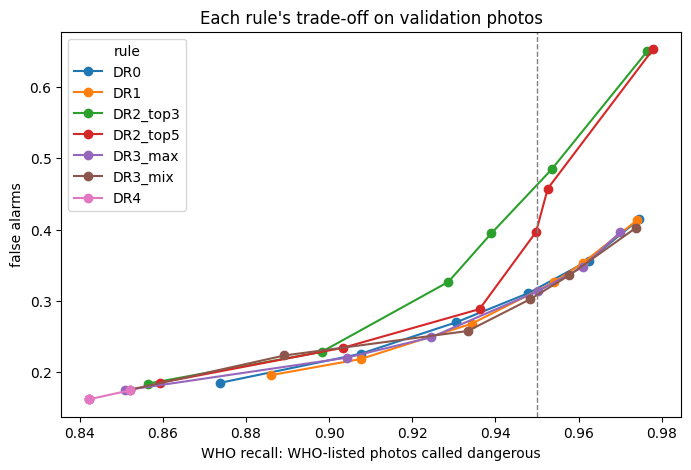

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
for rule in RULES:
    points = sorted((r["validation"]["who_recall"], r["validation"]["false_alarm"])
                    for by_bound in study["results"][rule].values() for r in by_bound.values()
                    if "unreachable" not in r)
    ax.plot(*zip(*points), marker="o", label=rule)
ax.axvline(0.95, color="grey", linestyle="--", linewidth=1)
ax.set(title="Each rule's trade-off on validation photos",
       xlabel="WHO recall: WHO-listed photos called dangerous", ylabel="false alarms")
ax.legend(title="rule")
fig.savefig(WORK / "dr" / "m3_decision_rules_H1_top1_s1.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Does the model look at the snake?

A model can score well by reading the scenery: a rocky hillside, a paddy field, the hand that holds the snake. We test this in two ways on every validation photo with a usable snake mask:

- **Snake blanked.** The snake's pixels are painted the average ImageNet grey, which is zero after the model's normalisation, and everything else stays. Of the photos the model gets right as they are, the share it still gets right is the **shortcut rate**: those answers cannot come from the snake.
- **Background swapped.** The snake's pixels are pasted, unchanged, onto the scenery of another validation photo of a different species, drawn with a fixed seed (that photo's own snake is blanked first). We count how often the model keeps its own answer and how often it follows the donor photo's species.

Validation photos have no hand-checked masks, so both tests use the front end's predicted masks. A mask that misses a tail tip or a coil leaves snake pixels behind, so both rates are upper bounds on how much the model leans on scenery. A blanked snake also leaves a grey silhouette whose outline the model could still read; for the swap we measure this directly, as how often the donor's blanked photo alone is called the donor's species.

We run both tests on the final model and on the whole-photo model.

In [23]:
FILL = (124, 116, 104)  # the ImageNet mean pixel: zero after the model's normalisation


def blank_snake(rgb, mask):
    blanked = rgb.copy()
    blanked[mask.astype(bool)] = FILL
    return blanked


def swap_background(rgb, mask, scenery):
    # the snake's own pixels on another photo's scenery, resized to this photo
    scenery = cv2.resize(np.ascontiguousarray(scenery), rgb.shape[1::-1],
                         interpolation=cv2.INTER_LINEAR)
    return np.where(mask.astype(bool)[..., None], rgb, scenery).astype(np.uint8)


def draw_donors(class_ids, eligible, seed=42):
    # per photo, a seeded eligible photo of another species; -1 when the photo is not eligible
    pool = np.flatnonzero(eligible)
    order = pool[np.argsort(class_ids[pool], kind="stable")]
    start, end = (np.searchsorted(class_ids[order], class_ids[pool], side=side)
                  for side in ("left", "right"))
    others = len(pool) - (end - start)
    draw = np.floor(np.random.default_rng(seed).random(len(pool)) * others).astype(int)
    position = np.where(draw < start, draw, draw + end - start)  # skip the photo's own species
    donors = np.full(len(class_ids), -1)
    donors[pool[others > 0]] = order[position[others > 0]]
    return donors

The validation photos with their predicted masks and boxes. Each photo also gets the flags for the slices we report: Indian photos, dark photos, blurry photos, and species that had at most 10 photographers in training (few photographers means few different looks at the species).

In [24]:
val_frame = data.with_files(data.build_frame(metadata, classes, ["val"], frontend_preds=preds,
                                             mask_source="predicted", preds_root=PREDS), DATA)
train_rows = metadata[(metadata["split"] == "train") & metadata["path"].isin(subset_paths)]
train_frame = data.cap_train(data.build_frame(train_rows, classes, ["train"]))  # as in training
taxa = class_tables(classes)
per_class = (pd.Series(photographer_groups(train_frame))
             .groupby(train_frame["class_id"].to_numpy()).nunique())
photographer_count = np.zeros(taxa.n_classes, dtype=int)
photographer_count[per_class.index.to_numpy(dtype=int)] = per_class.to_numpy()
few = photographer_count <= 10
flags = quality.set_index("path").loc[val_frame["path"]]
val_frame = val_frame.assign(india=val_frame["in_india"].astype(bool),
                             dark=flags["dark"].to_numpy(bool),
                             blurry=flags["blurry"].to_numpy(bool),
                             few_photographers=few[val_frame["class_id"].to_numpy()])
y_true, photo_groups = val_frame["class_id"].to_numpy(), photographer_groups(val_frame)
train_counts = np.bincount(train_frame["class_id"], minlength=taxa.n_classes)
val_counts = np.bincount(y_true, minlength=taxa.n_classes)
print(f"{len(val_frame):,} validation photos; {few.sum()} species with at most 10 photographers")
val_frame[["india", "dark", "blurry", "few_photographers"]].sum().rename("photos").to_frame()

17,151 validation photos; 29 species with at most 10 photographers


,photos
india,6367
dark,2292
blurry,701
few_photographers,119


Which photos have a predicted mask we can use: it must exist, have the photo's size and survive the same mask cleaning the training used. Each usable photo then gets its donor for the swap.

In [25]:
def mask_status(row):
    if not row.mask_file:
        return "none"
    try:
        with Image.open(row.mask_file) as image:
            if (image.height, image.width) != (row.height, row.width):
                return "size_mismatch"
    except (UnidentifiedImageError, ImportError):  # offline, ultralytics' open raises ImportError
        return "unreadable"
    cleaned = data.load_mask(row.mask_file, (row.height, row.width))
    return "usable" if cleaned is not None else "dropped_by_cleaning"


mask_warm = data.warm_cache(list(val_frame.loc[val_frame["mask_valid"], "mask_file"]))
with ThreadPoolExecutor(8) as pool:
    status = np.array(list(pool.map(mask_status, val_frame.itertuples(index=False))), dtype=object)
usable = status == "usable"
assert usable.any(), "no validation photo has a usable predicted mask"
donors = draw_donors(y_true, usable)
pd.Series(status).value_counts().rename("validation photos").to_frame()

,validation photos
usable,15977
none,1174


One validation photo in each condition, before the model's own crop and resize:

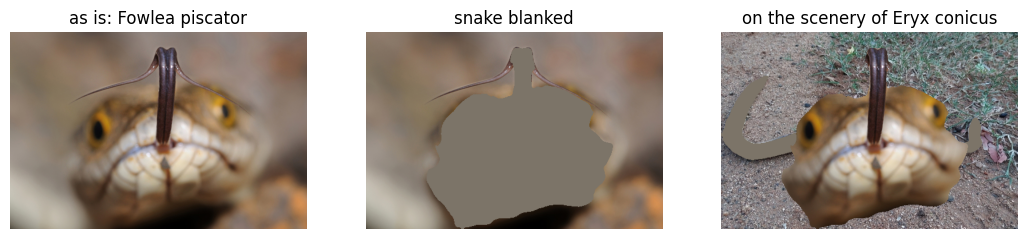

In [26]:
example = int(np.flatnonzero(usable)[0])
photo, donor = val_frame.iloc[example], val_frame.iloc[donors[example]]
rgb, donor_rgb = data.load_rgb(photo.image_file), data.load_rgb(donor.image_file)
mask = data.load_mask(photo.mask_file, rgb.shape[:2])
donor_mask = data.load_mask(donor.mask_file, donor_rgb.shape[:2])
panels = {f"as is: {photo.species}": rgb, "snake blanked": blank_snake(rgb, mask),
          f"on the scenery of {donor.species}":
              swap_background(rgb, mask, blank_snake(donor_rgb, donor_mask))}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, (title, image) in zip(axes, panels.items()):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
plt.show()

To score a condition, each photo is built exactly as the evaluation loader builds it (the exposure fix, the model's own input mode, the evaluation normalisation), with the snake blanked or swapped first. The model runs under the same mixed precision it was validated with.

In [27]:
INPUT_MODE = {"F0": "full", "F1": "box_crop"}  # the whole photo, or the detector's box
OUTPUT_KEYS = ("embedding", "species_logits", "who_logits", "genus_logits", "family_logits")


class ConditionPhotos(Dataset):
    # validation photos `rows` as one condition shows them to the model

    def __init__(self, condition, mode, size, rows):
        self.condition, self.mode, self.size, self.rows = condition, mode, size, rows

    def __len__(self):
        return len(self.rows)

    def photo(self, position):
        row = val_frame.iloc[position]
        rgb = data.load_rgb(row["image_file"])
        blanking = self.condition != "as_is"
        return row, rgb, data.load_mask(row["mask_file"], rgb.shape[:2]) if blanking else None

    def __getitem__(self, index):
        position = int(self.rows[index])
        row, rgb, mask = self.photo(position)
        if self.condition == "blanked":
            rgb = blank_snake(rgb, mask)
        elif self.condition == "swapped":
            _, donor_rgb, donor_mask = self.photo(int(donors[position]))
            rgb = swap_background(rgb, mask, blank_snake(donor_rgb, donor_mask))
        image, _ = data.apply_mode(rgb, None, self.mode, row["box"], self.size)
        return data.AUGMENT["eval"](image=image)["image"]

In [28]:
def one_opencv_thread(_):
    cv2.setNumThreads(0)


@torch.inference_mode()
def predict(model, photos, batch_size):
    loader = DataLoader(photos, batch_size=batch_size, num_workers=os.cpu_count(),
                        pin_memory=True, worker_init_fn=one_opencv_thread)
    collected = {name: [] for name in OUTPUT_KEYS}
    for images in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(images.to(DEVICE, non_blocking=True))
        for name in OUTPUT_KEYS:
            if out.get(name) is not None:
                collected[name].append(out[name].float())
    return {name: torch.cat(parts).cpu().numpy() for name, parts in collected.items() if parts}


def load_model(run):
    checkpoint = torch.load(run / "best.pt", map_location="cpu", weights_only=True)
    model = build_model(checkpoint["config"])
    model.load_state_dict(checkpoint["state_dict"])
    return checkpoint["config"], model.to(DEVICE).eval(), checkpoint.get("epoch")

Before blanking anything, the as-is pass must reproduce the run's own saved validation outputs, photo by photo: at least 99% the same top species (mixed precision can flip a near-tie). If it does not, we are not testing the run's model on the run's inputs, and the notebook stops. Each condition's per-photo outputs, verdicts included, are saved as its pass ends; the verdicts use the thresholds fitted on that run's own calibration photos.

In [29]:
def instrument_check(run, outputs):
    saved = load_outputs(run, "val_outputs")
    position = {path: index for index, path in enumerate(saved["paths"])}
    pairs = np.array([(row, position[path]) for row, path in enumerate(val_frame["path"])
                      if path in position], dtype=int).reshape(-1, 2)
    mine, theirs = outputs["species_logits"][pairs[:, 0]], saved["species_logits"][pairs[:, 1]]
    return {"photos": len(pairs),
            "top1_agreement": float((mine.argmax(1) == theirs.argmax(1)).mean()),
            "max_abs_logit_diff": float(np.abs(mine - theirs).max())}


def save_condition(file, rows, outputs, with_donor):
    kept = val_frame.iloc[rows]
    extra = {}
    if with_donor:
        extra = {"donor_path": val_frame["path"].to_numpy(str)[donors[rows]],
                 "donor_class_id": y_true[donors[rows]]}
    observers = kept["observer_id"].astype("string").fillna("").to_numpy(str)
    np.savez_compressed(file, paths=kept["path"].to_numpy(str), labels=kept["class_id"].to_numpy(),
                        observer_id=observers, **extra,
                        **{**outputs, "embedding": outputs["embedding"].astype(np.float16)})

In [30]:
def score_run(run):
    cfg, model, epoch = load_model(run)
    mode, size, batch = INPUT_MODE[cfg["front_end"]], cfg["input_size"], 2 * cfg["batch_size"]
    prototypes = np.load(run / "prototypes.npz")["plain"]
    calibration = load_outputs(run, "calib_outputs")
    thresholds = fit_thresholds(calibration, prototypes, tables, recall_bound="lower")
    rows = {"as_is": np.arange(len(val_frame)), "blanked": np.flatnonzero(usable),
            "swapped": np.flatnonzero(donors >= 0)}
    outputs, out_dir = {}, WORK / "r1" / run.name
    out_dir.mkdir(parents=True, exist_ok=True)
    for condition in rows:
        photos = ConditionPhotos(condition, mode, size, rows[condition])
        outputs[condition] = predict(model, photos, batch)
        verdicts = decide(outputs[condition], thresholds, prototypes, tables).label
        outputs[condition]["verdict"] = verdicts
        save_condition(out_dir / f"robustness_{condition}.npz", rows[condition], outputs[condition],
                       with_donor=condition == "swapped")
        if condition == "as_is":
            check = instrument_check(run, outputs["as_is"])
            assert check["top1_agreement"] >= 0.99, f"not the run's own model: {check}"
    return cfg, epoch, thresholds, rows, outputs, check

What we report from those outputs. Species scores (top-1, top-3, macro-F1, balanced accuracy) per condition, each with a 95% interval over photographers. For the blanked snake, the shortcut rate; for the swap, how often the model keeps its own species and how often it follows the donor's, next to two controls: how often it already named the donor's species before the swap, and the silhouette rate. And the verdicts: how often each one changes when the snake is blanked or the background is swapped.

In [31]:
VERDICTS = ("dangerous", "not_listed", "unknown")
NAN2 = [float("nan"), float("nan")]


def share(values):
    return float(np.mean(values)) if len(values) else float("nan")


def ci(fn, groups):
    return list(grouped_bootstrap(fn, groups)) if len(groups) else NAN2


def species_scores(labels, probs, groups):
    if not len(labels):
        return {"photos": 0, "photographers": 0, "top1": np.nan, "top3": np.nan,
                "macro_f1": np.nan, "balanced_acc": np.nan, "top1_ci": NAN2}
    report = species_report(labels, probs, train_counts, val_counts, taxa.tier)
    right = probs.argmax(axis=1) == labels
    return {"photos": len(labels), "photographers": int(np.unique(groups).size),
            **{key: report[key] for key in ("top1", "top3", "macro_f1", "balanced_acc")},
            "top1_ci": ci(lambda rows: share(right[rows]), groups)}


def shortcut_report(labels, as_is, blanked, groups):
    right, still = as_is == labels, blanked == labels
    return {"right_as_is": int(right.sum()), "shortcut_rate": share(still[right]),
            "shortcut_rate_ci": ci(lambda rows: share(still[rows][right[rows]]), groups),
            "blanked_top1": share(still), "changed_prediction": share(blanked != as_is)}

In [32]:
def donor_report(labels, donor_labels, as_is, swapped, groups, donor_blanked):
    # donor_blanked: the top species of each donor's own blanked photo (-1 when it has none)
    keeps, follows = swapped == labels, swapped == donor_labels
    known, silhouette = donor_blanked != -1, donor_blanked == donor_labels
    clean = known & ~silhouette
    return {"keeps_own_class": share(keeps),
            "keeps_own_class_ci": ci(lambda rows: share(keeps[rows]), groups),
            "follows_donor": share(follows),
            "follows_donor_ci": ci(lambda rows: share(follows[rows]), groups),
            "follows_donor_as_is": share(as_is == donor_labels),
            "keeps_own_among_right": share(keeps[as_is == labels]),
            "changed_prediction": share(swapped != as_is),
            "donor_silhouette_rate": share(silhouette[known]),
            "swaps_without_silhouette": int(clean.sum()),
            "follows_donor_without_silhouette": share(follows[clean])}


def verdict_counts(verdicts):
    return {label: int((np.asarray(verdicts) == label).sum()) for label in VERDICTS}


def verdict_change(before, after):
    return {"photos": len(before), "changed": share(before != after),
            "transitions": {f"{old}->{new}": int(((before == old) & (after == new)).sum())
                            for old in VERDICTS for new in VERDICTS if old != new},
            "before": verdict_counts(before), "after": verdict_counts(after)}

In [33]:
SLICES = ("india", "dark", "blurry", "few_photographers")


def slice_metrics(probs):
    # top-1 inside each slice against outside it; the gap's interval resamples photographers
    right = probs.argmax(axis=1) == y_true
    report = {}
    for name in SLICES:
        inside = val_frame[name].to_numpy(bool)
        sides = {side: species_scores(y_true[members], probs[members], photo_groups[members])
                 for side, members in (("in", inside), ("out", ~inside))}

        def gap(rows, inside=inside):
            return share(right[rows][inside[rows]]) - share(right[rows][~inside[rows]])

        report[name] = {**sides, "top1_gap": sides["in"]["top1"] - sides["out"]["top1"],
                        "top1_gap_ci": ci(gap, photo_groups)}
    return report

In [34]:
def conditions_report(rows, outputs):
    probs = {condition: softmax(o["species_logits"]) for condition, o in outputs.items()}
    top1 = {condition: p.argmax(axis=1) for condition, p in probs.items()}
    blanked_top1 = np.full(len(val_frame), -1)
    blanked_top1[rows["blanked"]] = top1["blanked"]
    india = val_frame["india"].to_numpy(bool)

    def scored(condition, members=None):
        members = np.arange(len(rows[condition])) if members is None else members
        picked = rows[condition][members]
        return species_scores(y_true[picked], probs[condition][members], photo_groups[picked])

    def shortcut(m):
        blanked = top1["blanked"][np.searchsorted(rows["blanked"], m)]
        return shortcut_report(y_true[m], top1["as_is"][m], blanked, photo_groups[m])

    def donor(m):
        swapped = top1["swapped"][np.searchsorted(rows["swapped"], m)]
        return donor_report(y_true[m], y_true[donors[m]], top1["as_is"][m], swapped,
                            photo_groups[m], blanked_top1[donors[m]])

    def by_india(report, m):
        return {"india": report(m[india[m]]), "not_india": report(m[~india[m]])}

    blanked, swapped = rows["blanked"], rows["swapped"]
    return {"as_is": scored("as_is"), "as_is_masked": scored("as_is", np.flatnonzero(usable)),
            "blanked": {**scored("blanked"), "shortcut": shortcut(blanked),
                        "by_india": by_india(shortcut, blanked)},
            "swapped": {**scored("swapped"), "as_is_same_photos": scored("as_is", swapped),
                        "donor": donor(swapped), "by_india": by_india(donor, swapped)}}

In [35]:
def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(2 ** 20), b""):
            digest.update(block)
    return digest.hexdigest()


def mask_counts(rows):
    misfit = status == "size_mismatch"
    return {"val": len(val_frame), "scored": len(val_frame), "with_mask": int(usable.sum()),
            "without_mask": int((~usable).sum()),
            "mask_dropped_by_cleaning": int((status == "dropped_by_cleaning").sum()),
            "mask_size_mismatch": int(misfit.sum()),
            "mask_size_mismatch_examples": val_frame.loc[misfit, "path"].head(5).tolist(),
            "mask_unreadable": int((status == "unreadable").sum()),
            "blanked": len(rows["blanked"]), "swapped": len(rows["swapped"]),
            "without_donor": int(usable.sum()) - len(rows["swapped"])}


def provenance(run, epoch):
    winners = PREDS / "summary.json"
    segmenter = (json.loads(winners.read_text()).get("winners", {}).get("S1", "not available")
                 if winners.exists() else "not available")
    return {"run_id": run.name, "run_dir": str(run), "checkpoint_epoch": epoch,
            "checkpoint_sha256": sha256(run / "best.pt"), "preds_root": str(PREDS),
            "frontend_preds_sha256": sha256(PREDS / "frontend_preds.csv"), "segmenter": segmenter}

In [36]:
def robustness_metrics(run, cfg, epoch, thresholds, rows, outputs, check, seconds):
    as_is = outputs["as_is"]["verdict"]
    return {
        "run": run.name, "front_end": cfg["front_end"], "input_mode": INPUT_MODE[cfg["front_end"]],
        "checkpoint_epoch": epoch, "provenance": provenance(run, epoch),
        "photos": mask_counts(rows), "instrument_check": check,
        "conditions": conditions_report(rows, outputs),
        "verdicts": {"recall_bound": "lower", "thresholds": asdict(thresholds),
                     "as_is": verdict_counts(as_is),
                     **{c: verdict_change(as_is[rows[c]], outputs[c]["verdict"])
                        for c in ("blanked", "swapped")}},
        "slices": slice_metrics(softmax(outputs["as_is"]["species_logits"])),
        "quality": {name: {"photos": len(g), "dark": float(g["dark"].mean()),
                           "blurry": float(g["blurry"].mean())}
                    for name, g in quality.groupby("set", sort=False)},
        "settings": {"fill_rgb": FILL, "dark_below": 60, "blur_below": 100.0, "swap_seed": 42,
                     "few_photographers_at_most": 10, "few_photographer_classes": int(few.sum()),
                     "prototype_set": "plain", "instrument_floor": 0.99},
        "warm_cache": mask_warm, "subset_hash": subset_hash, "versions": VERSIONS,
        "seconds": seconds}

Each model's results also go to a one-column summary (`summary.csv`), which we put side by side below.

In [37]:
def robustness_summary(m):
    c, v, s, p = m["conditions"], m["verdicts"], m["slices"], m["photos"]
    shortcut, india = c["blanked"]["shortcut"], c["blanked"]["by_india"]
    donor, few_rule = c["swapped"]["donor"], m["settings"]
    brackets = lambda pair: f"[{pair[0]:.3f}, {pair[1]:.3f}]"
    rates = lambda key: f"{india['india'][key]:.3f} / {india['not_india'][key]:.3f}"
    return pd.Series({
        "run": m["run"], "front end": m["front_end"], "segmenter": m["provenance"]["segmenter"],
        "val photos": p["val"], "with mask": p["with_mask"], "without mask": p["without_mask"],
        "masks dropped by cleaning / wrong size / unreadable":
            f"{p['mask_dropped_by_cleaning']} / {p['mask_size_mismatch']} / {p['mask_unreadable']}",
        "top-1 as is": c["as_is"]["top1"], "macro-F1 as is": c["as_is"]["macro_f1"],
        "top-1 as is (masked)": c["as_is_masked"]["top1"], "top-1 blanked": c["blanked"]["top1"],
        "macro-F1 blanked": c["blanked"]["macro_f1"], "shortcut rate": shortcut["shortcut_rate"],
        "shortcut 95% CI": brackets(shortcut["shortcut_rate_ci"]),
        "shortcut India / not": rates("shortcut_rate"),
        "top-1 swapped": c["swapped"]["top1"], "keeps own class": donor["keeps_own_class"],
        "follows donor": donor["follows_donor"],
        "donor class as is (control)": donor["follows_donor_as_is"],
        "donor silhouette rate": donor["donor_silhouette_rate"],
        "follows donor without silhouette": donor["follows_donor_without_silhouette"],
        "verdict changed, blanked": v["blanked"]["changed"],
        "dangerous -> not listed, blanked": v["blanked"]["transitions"]["dangerous->not_listed"],
        "unknown when blanked": v["blanked"]["after"]["unknown"] / v["blanked"]["photos"],
        "verdict changed, swapped": v["swapped"]["changed"],
        **{f"{name} gap": s[name]["top1_gap"] for name in s},
        **{f"{name} photos in / out": f"{s[name]['in']['photos']} / {s[name]['out']['photos']}"
           for name in s},
        "few-photographer classes (cut-off)": (f"{few_rule['few_photographer_classes']} "
                                               f"(<= {few_rule['few_photographers_at_most']})"),
        "India gap 95% CI": brackets(s["india"]["top1_gap_ci"]),
        "instrument top-1 agreement": m["instrument_check"]["top1_agreement"],
        "minutes": m["seconds"] / 60})

Now the GPU part: three passes over the validation photos for each of the two models (about 7 minutes per model on a T4).

In [38]:
assert torch.cuda.is_available(), "no GPU in this session"
r1, r1_summaries = {}, {}
for name, run in RUNS.items():
    started = time.perf_counter()
    cfg, epoch, thresholds, rows, outputs, check = score_run(run)
    metrics = robustness_metrics(run, cfg, epoch, thresholds, rows, outputs, check,
                                 time.perf_counter() - started)
    out_dir = WORK / "r1" / run.name
    r1[name] = write_json(out_dir / "robustness_metrics.json", metrics)
    r1_summaries[name] = robustness_summary(r1[name])
    r1_summaries[name].to_csv(out_dir / "summary.csv", header=False)
    conditions = r1[name]["conditions"]
    line = (f"{run.name}: photos {r1[name]['photos']}; as is {conditions['as_is']['top1']:.3f} "
            f"top-1; shortcut rate {conditions['blanked']['shortcut']['shortcut_rate']:.3f}; "
            f"follows donor {conditions['swapped']['donor']['follows_donor']:.3f}")
    (out_dir / "robustness.log").write_text(line + "\n")
    print(f"{name} model: the as-is pass agrees with the saved run on "
          f"{check['top1_agreement']:.2%} of photos; {time.perf_counter() - started:.0f} s")

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.4MB            

model.safetensors: downloading bytes:           |  0.00B            

final model: the as-is pass agrees with the saved run on 99.95% of photos; 353 s
whole_photo model: the as-is pass agrees with the saved run on 99.92% of photos; 361 s


The two models side by side. "Shortcut rate" is the share of right answers that survive blanking the snake; "keeps own class" and "follows donor" are for the swapped background, with the donor's species before the swap as the control; "verdict changed" counts photos whose verdict moves when the snake is blanked or the background swapped.

In [39]:
side_by_side = pd.concat({"whole-photo model": r1_summaries["whole_photo"],
                          "final model": r1_summaries["final"]}, axis=1)
side_by_side.drop(index=["run", "segmenter"])

,whole-photo model,final model
front end,F0,F1
val photos,17151,17151
with mask,15977,15977
without mask,1174,1174
masks dropped by cleaning / wrong size / unreadable,0 / 0 / 0,0 / 0 / 0
top-1 as is,0.53064,0.621946
macro-F1 as is,0.257462,0.366802
top-1 as is (masked),0.536521,0.62809
top-1 blanked,0.143456,0.127558
macro-F1 blanked,0.042001,0.042961


The slices, on the photos as they are: top-1 inside each slice minus top-1 outside it, with a 95% interval over photographers. A negative gap means the model does worse on that slice.

In [40]:
slice_names = {"india": "Indian photos", "dark": "dark photos", "blurry": "blurry photos",
               "few_photographers": "species with at most 10 photographers"}
models = {"whole_photo": "whole-photo model", "final": "final model"}
slice_rows = {}
for key, label in slice_names.items():
    row = {"photos in the slice": r1["final"]["slices"][key]["in"]["photos"]}
    for name, model_label in models.items():
        s = r1[name]["slices"][key]
        row[f"top-1 in the slice, {model_label}"] = round(s["in"]["top1"], 3)
        row[f"gap, {model_label} (95% interval)"] = (f"{s['top1_gap']:+.3f} "
                                                     f"({interval(s['top1_gap_ci'])})")
    slice_rows[label] = row
pd.DataFrame(slice_rows).T

,photos in the slice,"top-1 in the slice, whole-photo model","gap, whole-photo model (95% interval)","top-1 in the slice, final model","gap, final model (95% interval)"
Indian photos,6367,0.412,-0.188 (-0.229 to -0.150),0.524,-0.156 (-0.195 to -0.118)
dark photos,2292,0.57,+0.045 (0.001 to 0.092),0.654,+0.038 (-0.003 to 0.077)
blurry photos,701,0.583,+0.055 (-0.004 to 0.118),0.631,+0.009 (-0.051 to 0.074)
species with at most 10 photographers,119,0.227,-0.306 (-0.390 to -0.215),0.227,-0.398 (-0.487 to -0.306)


## 4. Video: does the verdict hold still?

On a phone the app reads live video, and a verdict that flickers between "dangerous" and "not listed" is worse than useless. We have no labelled snake videos, so we make them: 200 validation photos, taking the species in turn with a fixed seed, each become a 10-second clip at 15 frames per second. The recipe follows our first milestone: a moving camera with hand shake, motion blur, low light and noise, JPEG compression, and leaves that hide 30% to 70% of the snake. The leaves are placed on the front end's predicted mask; a photo without one gets them inside a central ellipse.

In [41]:
v = video  # a short name for the recipe table
recipe = {"source": "the first milestone gives seconds, fps and leaf_cover; the rest are ours",
          "seconds": v.CLIP_SECONDS, "fps": v.CLIP_FPS, "leaf_cover": v.LEAF_COVER_RANGE,
          "max_side": v.CLIP_MAX_SIDE, "path_keypoints": v.PATH_KEYPOINTS, "pan_max": v.PAN_MAX,
          "zoom": v.ZOOM_RANGE, "rotation_max_deg": v.ROTATION_MAX_DEG, "shake": v.SHAKE_RANGE,
          "shake_rotation_deg": v.SHAKE_ROTATION_DEG, "shake_persistence": v.SHAKE_PERSISTENCE,
          "exposure": v.EXPOSURE_RANGE, "max_blur_px": v.MAX_BLUR_PX,
          "light_gain": v.LIGHT_GAIN_RANGE, "srgb_gamma": v.SRGB_GAMMA,
          "noise_sigma": v.NOISE_SIGMA_RANGE, "jpeg_quality": v.JPEG_QUALITY_RANGE,
          "leaf_length": v.LEAF_LENGTH_RANGE, "leaf_aspect": v.LEAF_ASPECT_RANGE,
          "leaf_points": v.LEAF_POINTS, "leaf_tries": v.LEAF_TRIES,
          "leaf_green_low": v.LEAF_GREEN_LOW, "leaf_green_high": v.LEAF_GREEN_HIGH,
          "midrib_darken": v.MIDRIB_DARKEN, "centre_region": v.CENTRE_REGION,
          "order": "leaves on the scene, camera warp, motion blur, low light, noise, JPEG"}
pd.Series({key: str(value) for key, value in recipe.items()}, name="clip recipe").to_frame()

,clip recipe
source,"the first milestone gives seconds, fps and leaf_cover; the rest are ours"
seconds,10
fps,15
leaf_cover,"(0.3, 0.7)"
max_side,640
path_keypoints,4
pan_max,0.12
zoom,"(1.0, 1.35)"
rotation_max_deg,12.0
shake,"(0.002, 0.012)"


In [42]:
clips = video.round_robin(val_frame, 200, seed=42)
expected = [expected_verdict(class_id, tables) for class_id in clips["class_id"]]
print(f"{len(clips)} clips from {clips['species'].nunique()} species, "
      f"{expected.count('dangerous')} of them dangerous; "
      f"{clips['mask_valid'].mean():.0%} with a predicted mask for the leaves")

200 clips from 176 species, 51 of them dangerous; 96% with a predicted mask for the leaves


Four frames of the first clip:

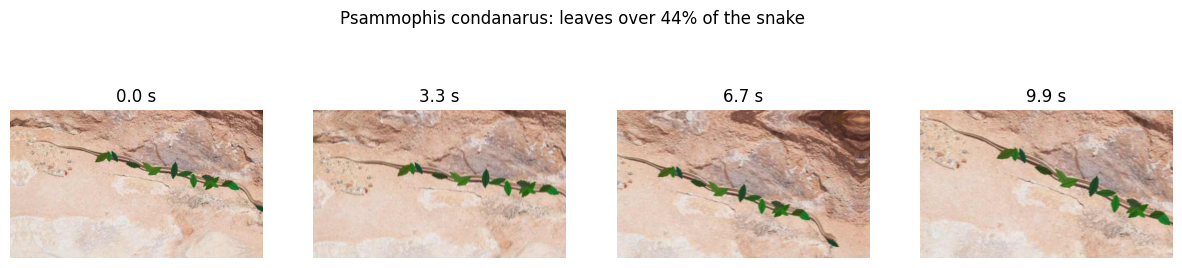

In [43]:
first = clips.iloc[0]
raw = load_raw_rgb(first.image_file)
clip = video.synthesize_clip(raw, data.load_mask(first.mask_file, raw.shape[:2]), seed=42)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, index in zip(axes, (0, 50, 100, 149)):
    ax.imshow(clip.frames[index])
    ax.set_title(f"{index / video.CLIP_FPS:.1f} s")
    ax.axis("off")
fig.suptitle(f"{first.species}: leaves over {clip.params['leaf_cover']:.0%} of the snake")
plt.show()

Every frame goes through the app's own steps: the exposure fix, the detector (the winner from the cropping notebook), the crop, the final model and the decision file's verdict. A frame whose best box is under the decision file's no-snake threshold, or that has no box, shows "no snake found": the model does not run on it and its verdict is "we don't know". The undistorted photo goes through the same steps, as a clean control.

In [44]:
front_dir = next(FRONT.rglob("winners.json")).parent
detector_file = front_dir / json.loads((front_dir / "winners.json").read_text())["D1"]["weights"]
assert detector_file.is_file(), f"the detector {detector_file} is missing"
detector = YOLO(str(detector_file))
snake_class = [index for index, name in detector.names.items()
               if str(name).strip().lower() == "snake"]
assert len(snake_class) == 1, detector.names
final_cfg, final_model, _ = load_model(RUNS["final"])
assert INPUT_MODE[final_cfg["front_end"]] == "box_crop"


@torch.inference_mode()
def read_frame(rgb):
    # one frame through the app; None when no snake is found
    fixed = data.fix_exposure(rgb)
    boxes = detector.predict(cv2.cvtColor(fixed, cv2.COLOR_RGB2BGR), conf=0.05, classes=snake_class,
                             rect=False, verbose=False)[0].boxes
    if not len(boxes) or float(boxes.conf.max()) < tau_snake:
        return None
    box = tuple(float(value) for value in boxes.xyxy[int(boxes.conf.argmax())].tolist())
    image, _ = data.apply_mode(fixed, None, "box_crop", box, final_cfg["input_size"])
    out = final_model(data.AUGMENT["eval"](image=image)["image"].unsqueeze(0).to(DEVICE))
    return {name: out[name].float().cpu().numpy() for name in OUTPUT_KEYS
            if out.get(name) is not None}


print(f"detector {detector_file.relative_to(FRONT)}; no snake under box confidence {tau_snake}")

detector frontends/D1/yolo26n-ft/detector.pt; no snake under box confidence 0.102


Three ways to turn frames into the verdict on screen:

- **per frame**: each frame's own verdict;
- **EMA**: an exponential moving average (weight 0.3 on the newest frame) of the model's probabilities and embedding, then the verdict;
- **4-of-6 vote**: a verdict shows only while it is the verdict of at least 4 of the last 6 frames; otherwise the screen says "we don't know", never a stale verdict.

Each also gives a species, smoothed the same way.

In [45]:
METHODS = ("per_frame", "ema", video.VOTE)
METHOD_TEXT = {
    "per_frame": "each frame's own verdict and top-1",
    "ema": "EMA (alpha 0.3) of every head's probabilities and the embedding, then decide",
    video.VOTE: f"a label shows while it fills {video.VOTE_K} of the last {video.VOTE_N} "
                "per-frame labels; otherwise 'unknown' (species -1), never a stale label"}


def ema(values, alpha=0.3):
    smoothed = np.asarray(values, dtype=float).copy()
    for t in range(1, len(smoothed)):
        smoothed[t] = alpha * smoothed[t] + (1 - alpha) * smoothed[t - 1]
    return smoothed


def smoothed_outputs(outputs):
    # the EMA of each head's probabilities, back as logits that give those probabilities again
    temperatures = {"species_logits": final_thresholds.temperature, "genus_logits": 1.0,
                    "who_logits": final_thresholds.temperature_who, "family_logits": 1.0}
    smoothed = {"embedding": ema(outputs["embedding"])}
    for name, temperature in temperatures.items():
        if name in outputs:
            probs = ema(softmax(np.asarray(outputs[name], dtype=float) / temperature))
            smoothed[name] = temperature * np.log(np.maximum(probs, 1e-12))
    return smoothed

In [46]:
def frame_verdicts(outputs, snake):
    # each method's verdict and species per frame; `outputs` hold only the frames with a snake
    rows = np.flatnonzero(snake)
    verdicts = {method: ["unknown"] * len(snake) for method in METHODS[:2]}
    species = {method: [-1] * len(snake) for method in METHODS[:2]}
    if len(rows):
        for method, frames in (("per_frame", outputs), ("ema", smoothed_outputs(outputs))):
            decided = decide(frames, final_thresholds, final_prototypes, tables)
            for position, row in enumerate(rows):
                verdicts[method][row] = str(decided.label[position])
                species[method][row] = int(decided.top1[position])
    k, n = video.VOTE_K, video.VOTE_N
    verdicts[video.VOTE] = video.vote_k_of_n(verdicts["per_frame"], k, n, fallback="unknown")
    species[video.VOTE] = video.vote_k_of_n(species["per_frame"], k, n, fallback=-1)
    return verdicts, species

Two schedules. On a fast GPU every frame is read. On the laptop we target, the app is still busy with one frame when the next ones arrive, so it skips frames: it always takes the newest frame once it is free. The laptop's time per frame is the deployed package's one-thread figure, read from the committed laptop timing table (`results/m3/x1_laptop/package.csv`).

In [47]:
package = pd.read_csv(REPO / "results" / "m3" / "x1_laptop" / "package.csv")
deployed = package[(package["precision"] == "deployment")
                   & (package["encoder"] == final_cfg["encoder"])
                   & (package["front_end"] == "yolo26n-ft@320")]
assert len(deployed) == 1, f"package.csv must hold one deployment row for {final_cfg['encoder']}"
laptop_keys = ["precision", "encoder", "snakeid_int8", "size", "front_end", "front_end_precision",
               "pipeline_ms_1t", "pipeline_ms_4t", "latency_device"]
laptop = {"file": "results/m3/x1_laptop/package.csv", "figure": "pipeline_ms_1t",
          **deployed.iloc[0][laptop_keys].to_dict()}
schedules = {"every_frame": 0.0, "laptop_cpu": laptop["pipeline_ms_1t"] / 1000}
print(f"laptop ({laptop['latency_device']}): {laptop['pipeline_ms_1t']:.1f} ms per frame on one "
      f"thread, so at most {1000 / laptop['pipeline_ms_1t']:.1f} of the {video.CLIP_FPS} frames "
      f"per second are read")

laptop (laptop CPU (Apple M4 Pro)): 84.9 ms per frame on one thread, so at most 11.8 of the 15 frames per second are read


One clip end to end: every frame is read once, then each schedule picks the frames it would have read, and each method's verdicts are scored with `video_metrics`: how many times the verdict flips, when it first stays on screen for a full second (stable), and whether the last stable verdict is right. The right verdict is "dangerous" for a species in the danger table and "not listed" otherwise; "we don't know" never counts as right.

In [48]:
def run_clip(photo, seed):
    raw = load_raw_rgb(photo.image_file)
    clean = read_frame(raw)
    clean = None if clean is None else decide(clean, final_thresholds, final_prototypes, tables)
    clip = video.synthesize_clip(raw, data.load_mask(photo.mask_file, raw.shape[:2]), seed=seed)
    found_frames = [read_frame(frame) for frame in clip.frames]
    snake = np.array([out is not None for out in found_frames])
    with_snake = [out for out in found_frames if out is not None]
    outputs = {key: np.concatenate([out[key] for out in with_snake])
               for key in (with_snake[0] if with_snake else ())}
    row_of = np.cumsum(snake) - 1  # each snake frame's row in outputs
    record = {"params": clip.params, "no_snake_frames": int((~snake).sum()), "schedules": {},
              "clean_verdict": "unknown" if clean is None else str(clean.label[0]),
              "clean_top1": -1 if clean is None else int(clean.top1[0])}
    rows = []
    for name, latency in schedules.items():
        processed, shown = video.schedule(len(clip.frames), video.CLIP_FPS, latency)
        kept = snake[processed]
        chosen = {key: value[row_of[processed[kept]]] for key, value in outputs.items()}
        verdicts, species = frame_verdicts(chosen, kept)
        record["schedules"][name] = {"processed": processed, "shown": shown, "snake": kept,
                                     "verdicts": verdicts, "species": species}
        rows += clip_rows(photo, record, name)
    return record, rows

In [49]:
def clip_rows(photo, record, schedule_name):
    params, frames = record["params"], record["schedules"][schedule_name]
    class_id, end = int(photo.class_id), params["frames"] / params["fps"]
    expected = expected_verdict(class_id, tables)
    rows = []
    for method in METHODS:
        verdicts, species = frames["verdicts"][method], frames["species"][method]
        scores = {"verdict": video.video_metrics(verdicts, expected, frames["shown"], end),
                  "species": video.video_metrics(species, class_id, frames["shown"], end)}
        rows.append({
            "path": photo.path, "class_id": class_id,
            "observer_id": "" if pd.isna(photo.observer_id) else str(photo.observer_id),
            "clip_seed": params["seed"], "schedule": schedule_name, "method": method,
            "frames": params["frames"], "frames_processed": len(frames["processed"]),
            "no_snake_frames": record["no_snake_frames"],
            "no_snake_processed": int((~frames["snake"]).sum()),
            "effective_fps": len(frames["processed"]) / end,
            "dangerous": bool(tables.dangerous[class_id]), "expected_verdict": expected,
            "ever_not_listed": "not_listed" in verdicts, "clean_verdict": record["clean_verdict"],
            "clean_top1": record["clean_top1"],
            "clean_verdict_correct": record["clean_verdict"] == expected,
            "clean_species_correct": record["clean_top1"] == class_id,
            **{f"{kind}_{key}": value for kind, result in scores.items()
               for key, value in result.items()}})
    return rows

All 200 clips (about 20 minutes on a T4). Each clip's rows are added to `video_clips.csv` as it finishes; a photo that fails is counted and listed, never silently dropped.

In [50]:
assert torch.cuda.is_available(), "no GPU in this session"
V1 = WORK / "v1" / "H1_top1_s1"
V1.mkdir(parents=True, exist_ok=True)
clips_csv = V1 / "video_clips.csv"
clips_csv.unlink(missing_ok=True)
started, records, errors = time.time(), {}, []
for index, photo in enumerate(clips.itertuples(index=False)):
    try:
        records[photo.path], rows = run_clip(photo, 42 + index)  # clip seeds 42, 43, ...
    except Exception as error:  # one bad photo must not end the run; it is reported below
        errors.append({"path": photo.path, "error": f"{type(error).__name__}: {error}"})
        continue
    pd.DataFrame(rows).to_csv(clips_csv, mode="a", header=not clips_csv.exists(), index=False)
minutes = (time.time() - started) / 60
print(f"{len(records)} of {len(clips)} clips in {minutes:.1f} min; {len(errors)} failed")
errors

200 of 200 clips in 22.3 min; 0 failed


[]

The per-clip rows, summed up per schedule and method. "Stable within 2 s" and "at most 1 flip" are the targets from our first milestone; the clip-correct share has a 95% interval over photographers.

In [51]:
def rate(flags):
    flags = np.asarray(flags, dtype=bool)
    return float(flags.mean()) if flags.size else None


def label_summary(c, kind):
    flips = c[f"{kind}_flips"].to_numpy(dtype=float)
    stable_at, confirmed_at = (pd.to_numeric(c[f"{kind}_{when}"], errors="coerce").to_numpy(float)
                               for when in ("time_to_stable", "time_to_confirmed"))
    correct = c[f"{kind}_clip_correct"].to_numpy(bool)
    clean = c[f"clean_{kind}_correct"].to_numpy(bool)
    stable = np.isfinite(stable_at)
    within = lambda times: rate(stable & (np.nan_to_num(times, nan=np.inf) <= 2.0))
    median = lambda times: float(np.median(times[stable])) if stable.any() else None
    right = lambda rows: float(correct[rows].mean())
    return {"mean_flips": float(flips.mean()), "median_flips": float(np.median(flips)),
            "o6_flips_share": rate(flips <= 1), "stable_share": rate(stable),
            "median_time_to_stable": median(stable_at),
            "median_time_to_confirmed": median(confirmed_at),
            "o6_stable_share": within(stable_at), "o6_confirmed_share": within(confirmed_at),
            "clip_correct": rate(correct),
            "clip_correct_ci": list(grouped_bootstrap(right, photographer_groups(c))),
            "frames_correct": float(c[f"{kind}_frames_correct"].mean()),
            "clean_correct": rate(clean), "clip_correct_where_clean_correct": rate(correct[clean])}

In [52]:
def method_summary(c):
    dangerous = c[c["dangerous"]]
    return {"verdict": label_summary(c, "verdict"), "species": label_summary(c, "species"),
            "dangerous_clips": len(dangerous),
            "dangerous_ever_not_listed": rate(dangerous["ever_not_listed"]),
            "dangerous_final_not_listed": rate(dangerous["verdict_final_stable"] == "not_listed")}


def schedule_summary(c, latency):
    first_method = c[c["method"] == METHODS[0]]
    fps = float(first_method["effective_fps"].mean())
    read = first_method["frames_processed"]
    return {"latency_seconds": float(np.mean(latency)),
            "latency_median_seconds": float(np.median(latency)), "effective_fps": fps,
            "skipped_share": float(1 - (read / first_method["frames"]).mean()),
            "no_snake_processed_share": float((first_method["no_snake_processed"] / read).mean()),
            "meets_target_fps": fps >= video.TARGET_FPS,
            "methods": {method: method_summary(c[c["method"] == method]) for method in METHODS}}

In [53]:
clip_table = pd.read_csv(clips_csv, dtype={"observer_id": str})
done = [records[path] for path in clips["path"] if path in records]
params, no_snake_frames = [r["params"] for r in done], [r["no_snake_frames"] for r in done]
frames_total = sum(p["frames"] for p in params)
detector_name = str(detector_file.relative_to(FRONT))
run_info = {"run_kernel": "dataset:puneetbajajiitm/serpentguard-m3-run-final",
            "run": final_cfg["run_id"], "config": final_cfg, "recall_bound": "lower",
            "subset_hash": subset_hash, "device": str(DEVICE), "gpu": VERSIONS["gpu"],
            "preds_kernel": "puneetbajajiitm/sg-m3-frontends", "mask_source": "predicted",
            "detector": detector_name, "tau_snake": tau_snake, "laptop_latency": laptop}
decision = {"thresholds": asdict(final_thresholds), "prototype_set": "plain", "scorer": "head",
            "prototype_scale": None, "recall_bound": "lower",
            "front_end": {"mode": "box_crop", "detector": detector_name,
                          "detector_sha256": sha256(detector_file), "tau_snake": tau_snake},
            "expected_verdict": "dangerous for a danger-table species, not_listed otherwise; "
                                "unknown is never right"}
no_snake = {"frames": sum(no_snake_frames), "frames_total": frames_total,
            "share": sum(no_snake_frames) / frames_total if frames_total else None,
            "clips_with_no_snake_frames": sum(n > 0 for n in no_snake_frames),
            "clean_no_snake": sum(r["clean_top1"] == -1 for r in done)}

In [54]:
v1 = write_json(V1 / "video_metrics.json", {
    "run_info": run_info, "photos": len(clips), "clips": len(records), "errors": errors,
    "classes": int(clips.loc[clips["path"].isin(records), "class_id"].nunique()), "seed": 42,
    "photos_hash": hashlib.sha256("\n".join(sorted(clips["path"])).encode()).hexdigest(),
    "checkpoint_sha256": sha256(RUNS["final"] / "best.pt"), "recipe": recipe,
    "methods": METHOD_TEXT,
    "stability": f"a label is stable once it stays {video.STABLE_SECONDS} s; time_to_stable is "
                 f"when the first stable label shows, time_to_confirmed when it has stayed "
                 f"{video.STABLE_SECONDS} s, clip_correct whether the last stable label is right",
    "decision": decision, "no_snake": no_snake,
    "clean_control": "clean_* columns: the model on the undistorted photo, through the same steps",
    "o6_targets": {"fps": video.TARGET_FPS, "max_flips": 1, "stable_within_seconds": 2.0},
    "versions": VERSIONS, "occluder_regions": dict(Counter(p["occluder_region"] for p in params)),
    "leaf_cover_below_range": sum(p["leaf_cover"] < video.LEAF_COVER_RANGE[0] for p in params),
    "schedules": {name: schedule_summary(clip_table[clip_table["schedule"] == name], latency)
                  for name, latency in schedules.items()},
    "clip_params": params})
print(f"no snake found on {no_snake['frames']:,} of {frames_total:,} frames, in "
      f"{no_snake['clips_with_no_snake_frames']} clips; leaves placed on {v1['occluder_regions']}")

no snake found on 1,898 of 30,000 frames, in 95 clips; leaves placed on {'mask': 191, 'centre': 9}


The per-frame verdicts and species of every clip and schedule are saved too, so any clip metric can be recomputed without the model.

In [55]:
codes = {label: code for code, label in enumerate(VERDICTS)}
entries = [(path, name, frames) for path, record in records.items()
           for name, frames in record["schedules"].items()]
per_clip = list(records.values())
arrays = {"verdict_names": np.array(VERDICTS), "clip_paths": np.array(list(records)),
          "clip_params": np.array([json.dumps(r["params"]) for r in per_clip]),
          "clean_verdict": np.array([codes[r["clean_verdict"]] for r in per_clip], np.int8),
          "clean_top1": np.array([r["clean_top1"] for r in per_clip], np.int32),
          "clip_no_snake": np.array([r["no_snake_frames"] for r in per_clip], np.int32),
          "paths": np.array([path for path, _, _ in entries]),
          "schedules": np.array([name for _, name, _ in entries]),
          "offsets": np.cumsum([0] + [len(f["processed"]) for _, _, f in entries]).astype(np.int64)}
for key, dtype in (("processed", np.int32), ("shown", np.float64), ("snake", bool)):
    arrays[key] = np.concatenate([f[key] for _, _, f in entries]).astype(dtype)
for method in METHODS:
    arrays[f"verdict_{method}"] = np.array([codes[label] for _, _, f in entries
                                            for label in f["verdicts"][method]], np.int8)
    arrays[f"top1_{method}"] = np.concatenate([f["species"][method] for _, _, f in entries]
                                              ).astype(np.int32)
np.savez_compressed(V1 / "video_frames.npz", **arrays)
print(f"{len(entries)} clip-schedule pairs, {arrays['offsets'][-1]:,} frames read in all")

400 clip-schedule pairs, 53,600 frames read in all


The comparison. "Flips" counts how often the verdict on screen changes in a 10-second clip; "dangerous ever 'not listed'" is the share of dangerous snakes' clips that showed "not listed" at least once, the mistake that matters most.

In [56]:
video_rows = []
for name, s in v1["schedules"].items():
    for method, m in s["methods"].items():
        verdict, species = m["verdict"], m["species"]
        video_rows.append({
            "schedule": name, "method": method, "effective FPS": s["effective_fps"],
            "skipped": s["skipped_share"], "verdict flips (mean)": verdict["mean_flips"],
            "verdict <= 1 flip": verdict["o6_flips_share"],
            "verdict stable <= 2 s": verdict["o6_stable_share"],
            "verdict confirmed <= 2 s": verdict["o6_confirmed_share"],
            "verdict clip correct": verdict["clip_correct"],
            "verdict clean correct": verdict["clean_correct"],
            "verdict clip correct where clean correct": verdict["clip_correct_where_clean_correct"],
            "species flips (mean)": species["mean_flips"],
            "species clip correct": species["clip_correct"],
            "species clean correct": species["clean_correct"],
            "dangerous ever 'not listed'": m["dangerous_ever_not_listed"],
            "dangerous final 'not listed'": m["dangerous_final_not_listed"]})
video_summary = pd.DataFrame(video_rows).set_index(["schedule", "method"])
video_summary.to_csv(V1 / "summary.csv")
shown = ["effective FPS", "verdict flips (mean)", "verdict <= 1 flip", "verdict stable <= 2 s",
         "verdict clip correct", "verdict clean correct", "dangerous ever 'not listed'"]
video_summary[shown].round(3)

effective FPS  verdict flips (mean)  \
schedule    method                                             
every_frame per_frame             15.0                33.230   
            ema                   15.0                15.485   
            vote_4_of_6           15.0                 7.665   
laptop_cpu  per_frame             11.8                26.195   
            ema                   11.8                12.065   
            vote_4_of_6           11.8                 6.085   

                         verdict <= 1 flip  verdict stable <= 2 s  \
schedule    method                                                  
every_frame per_frame                0.170                  0.595   
            ema                      0.330                  0.810   
            vote_4_of_6              0.385                  0.945   
laptop_cpu  per_frame                0.180                  0.630   
            ema                      0.370                  0.830   
            vote_4_of_6              0.405                  0.930   

                         verdict clip correct  verdict clean correct  \
schedule    method                                                     
every_frame per_frame                   0.285                  0.585   
            ema                         0.305                  0.585   
            vote_4_of_6                 0.295                  0.585   
laptop_cpu  per_frame                   0.280                  0.585   
            ema                         0.290                  0.585   
            vote_4_of_6                 0.295                  0.585   

                         dangerous ever 'not listed'  
schedule    method                                    
every_frame per_frame                          0.294  
            ema                                0.078  
            vote_4_of_6                        0.078  
laptop_cpu  per_frame                          0.294  
            ema                                0.078  
            vote_4_of_6                        0.059

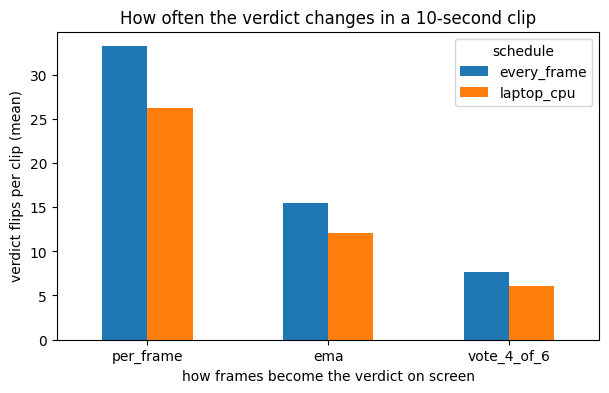

In [57]:
flips = video_summary["verdict flips (mean)"].unstack("schedule").loc[list(METHODS)]
ax = flips.plot.bar(rot=0, figsize=(7, 4))
ax.set(title="How often the verdict changes in a 10-second clip",
       xlabel="how frames become the verdict on screen", ylabel="verdict flips per clip (mean)")
ax.legend(title="schedule")
plt.show()

## 5. Summary

The headline number from each part, side by side.

In [58]:
lower_fit = {rule: rows["lower"] for rule, rows in study["headline"]["rows"].items()}
laptop_runs = v1["schedules"]["laptop_cpu"]["methods"]
shortcut = {name: r1[name]["conditions"]["blanked"]["shortcut"]["shortcut_rate"] for name in r1}
pd.Series({
    "WHO-listed photos called dangerous (target 0.95)":
        reports["head"]["verdict_metrics"]["who_dangerous_recall"],
    "false alarms, current rule": lower_fit["DR0"]["false_alarm"],
    "false alarms, best other rule that keeps the verdicts' meaning":
        min(row["false_alarm"] for rule, row in lower_fit.items() if rule not in ("DR0", "DR4")),
    "unknown-species photos flagged (target 0.70)":
        reports["head"]["u1"]["groups"]["all"]["flagged_at_tau"],
    "shortcut rate, whole-photo model": shortcut["whole_photo"],
    "shortcut rate, final model": shortcut["final"],
    "verdict flips per clip on the laptop, per frame":
        laptop_runs["per_frame"]["verdict"]["mean_flips"],
    "verdict flips per clip on the laptop, 4-of-6 vote":
        laptop_runs[video.VOTE]["verdict"]["mean_flips"],
    "clip verdict right on the laptop, 4-of-6 vote":
        laptop_runs[video.VOTE]["verdict"]["clip_correct"],
}, name="value").round(3).to_frame()

,value
WHO-listed photos called dangerous (target 0.95),0.948
"false alarms, current rule",0.311
"false alarms, best other rule that keeps the verdicts' meaning",0.302
unknown-species photos flagged (target 0.70),0.075
"shortcut rate, whole-photo model",0.236
"shortcut rate, final model",0.178
"verdict flips per clip on the laptop, per frame",26.195
"verdict flips per clip on the laptop, 4-of-6 vote",6.085
"clip verdict right on the laptop, 4-of-6 vote",0.295


## What we found

The final model calls about 95% of WHO-listed snakes dangerous on validation, just under the 0.95 target, but it also raises a false alarm on about 3 in 10 snakes that are neither WHO-listed nor vipers or elapids. None of the six other decision rules lowers those false alarms by more than chance at the same WHO recall; the one rule that cuts them clearly (DR4) does it by answering "we don't know" far more often and calling fewer WHO-listed snakes dangerous, so we keep the current rule. Blanking the snake shows that the final model leans on scenery less than the whole-photo model, but some of its right answers still survive without the snake, and it is clearly weaker on Indian photos and on species with few photographers. On damaged video the 4-of-6 vote makes the verdict several times steadier than reading frames one by one, yet the clip's final verdict is right only about 3 times in 10, so a verdict from video needs the same caution as a poor photo.